
## Term Project - Milestone 5

### Merging the Data and Storing in a Database/Visualizing Data

Now that you have cleaned and transformed your 3 datasets, you need to load them into a database. You can choose what kind of database (SQLLite or MySQL, Postgre SQL are all free options). You will want to load each dataset into SQL Lite as an individual table and then you must join the datasets together with SQL joins into 1 dataset.


First I will read in all the saved off files I created from my previous milestones.

In [22]:
# required libraries
import pandas as pd
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# first read in all of my csv files from my previous milestone work
tmdb = pd.read_csv('movies_cleaned.csv')
bom = pd.read_csv('box_office_mojo.csv')
omdb = pd.read_csv('omdb_cleaned.csv')

In [23]:
# load dataframes from the cleaned CSVs
tmdb = pd.read_csv('movies_cleaned.csv')
omdb = pd.read_csv('omdb_cleaned.csv')
bom = pd.read_csv('box_office_mojo.csv') 

# connect to SQLite and load tables
conn = sqlite3.connect('movie_analysis.db')

# sql table for every dataframe/movie source
tmdb.to_sql('tmdb', conn, if_exists='replace', index=False)
omdb.to_sql('omdb', conn, if_exists='replace', index=False)
bom.to_sql('bom', conn, if_exists='replace', index=False)

# master SQL JOIN
# TMDB is my base datasource
# use LEFT JOIN to keep all TMDB records and match data from other sources
query = """
SELECT 
    t.Movie_Title,
    t.Budget_USD,
    t.Revenue_USD AS TMDB_Revenue,
    b.Lifetime_Gross AS Scraped_Gross,
    o.IMDb_Rating,
    o.RT_Score,
    o.Award_Status,
    o.Metacritic_Score,
    t.Simplified_Title
FROM tmdb t
LEFT JOIN bom b ON t.Simplified_Title = b.Simplified_Title
LEFT JOIN omdb o ON t.Simplified_Title = o.Simplified_Title
"""

all_movies = pd.read_sql_query(query, conn)
conn.close()

print(f"Merge Complete: {len(all_movies)} records in the consolidated dataset.")

Merge Complete: 3260 records in the consolidated dataset.


## Visualizations

Create 5 visualizations that demonstrate the data you have cleansed. You should have at least 2 visualizations that have data from more than one source, using SQL joins (meaning, if you have 3 tables, you must have visualizations that span across 2 of the tables – you are also welcome to use your consolidated dataset that you created in the previous step, if you do that, you have met this requirement).

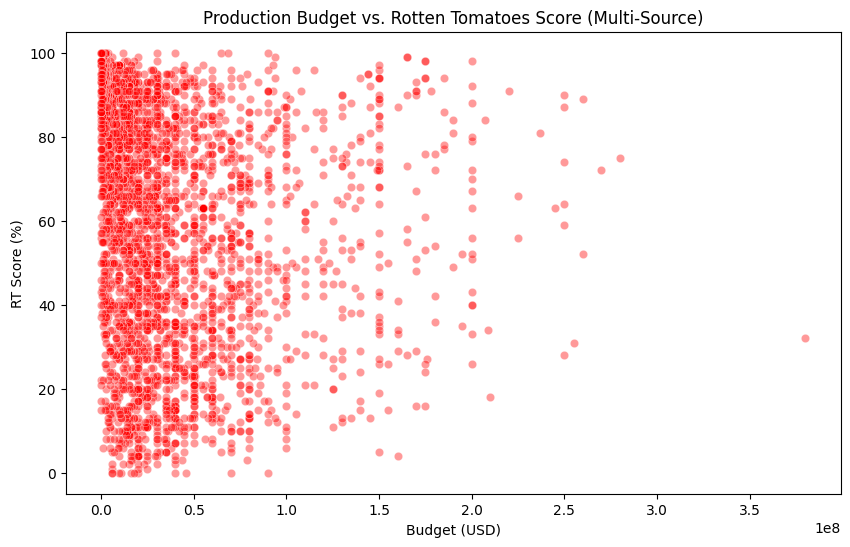

In [24]:
# First Visualization - Multi-Source: Budget (TMDB) vs. RT Score (OMDB)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=all_movies, x='Budget_USD', y='RT_Score', alpha=0.4, color='red')
plt.title('Production Budget vs. Rotten Tomatoes Score (Multi-Source)')
plt.xlabel('Budget (USD)')
plt.ylabel('RT Score (%)')
plt.show()

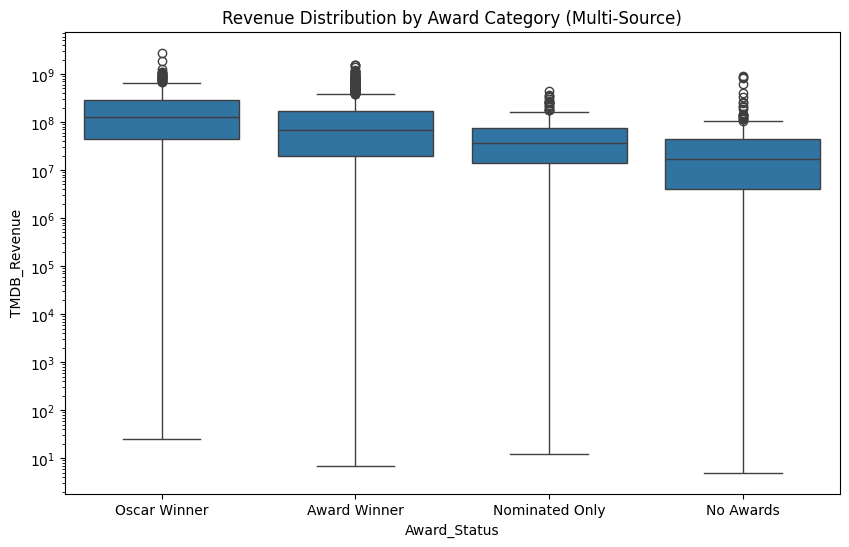

In [25]:
# Second Visualization - Multi-Source: Award Status (OMDB) vs. TMDB Revenue (TMDB)
plt.figure(figsize=(10, 6))
sns.boxplot(data=all_movies, x='Award_Status', y='TMDB_Revenue')
# log scale to handle massive revenue outliers
plt.yscale('log') 
plt.title('Revenue Distribution by Award Category (Multi-Source)')
plt.show()

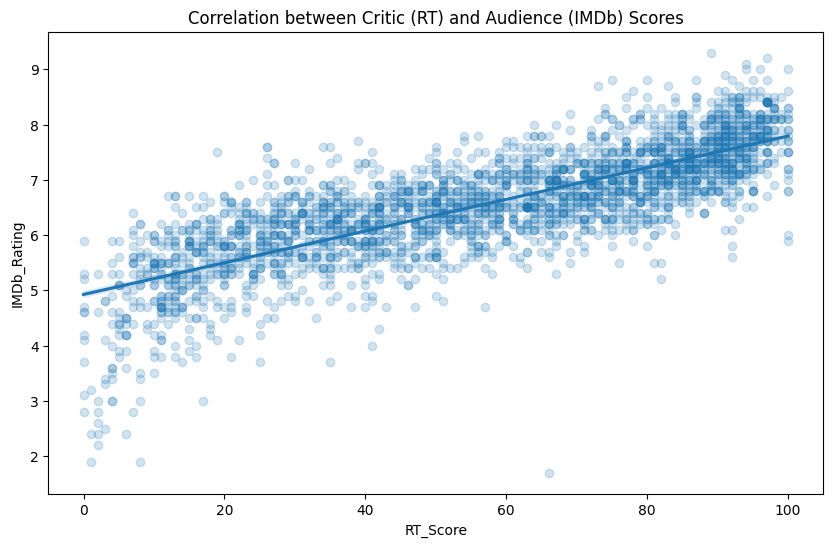

In [26]:
# Third Visualization - Correlation: IMDb vs. RT Score (OMDB Source)
plt.figure(figsize=(10, 6))
sns.regplot(data=all_movies, x='RT_Score', y='IMDb_Rating', scatter_kws={'alpha':0.2})
plt.title('Correlation between Critic (RT) and Audience (IMDb) Scores')
plt.show()

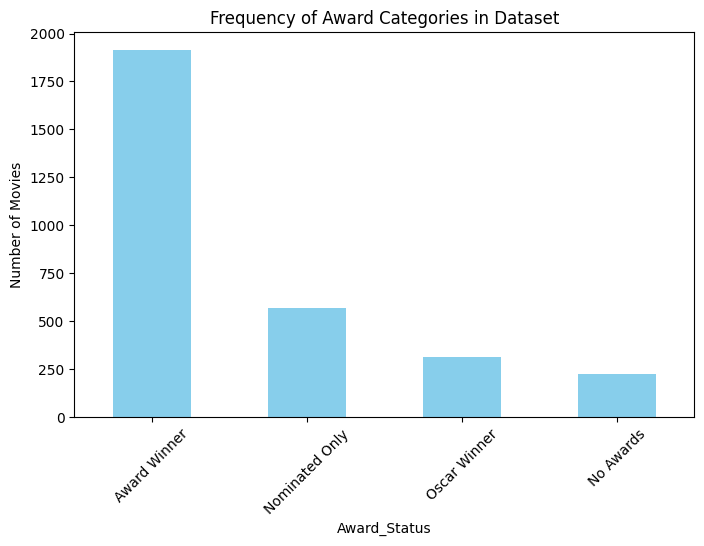

In [27]:
# Fourth Visualization - Distribution: Count of Movies by Award Status
plt.figure(figsize=(8, 5))
all_movies['Award_Status'].value_counts().plot(kind='bar', color='skyblue')
plt.title('Frequency of Award Categories in Dataset')
plt.ylabel('Number of Movies')
plt.xticks(rotation=45)
plt.show()

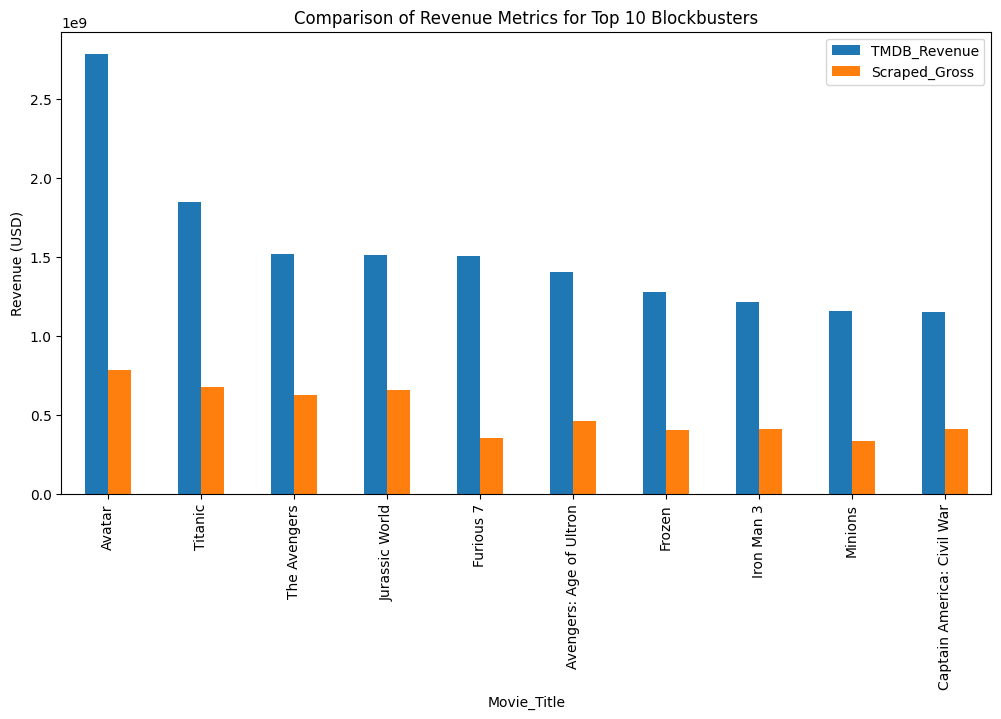

In [28]:
# Fifth Visualization - Financials: Top 10 Highest Grossing (Scraped Gross vs TMDB Revenue)
top_10 = all_movies.nlargest(10, 'TMDB_Revenue')
top_10.plot(x='Movie_Title', y=['TMDB_Revenue', 'Scraped_Gross'], kind='bar', figsize=(12, 6))
plt.title('Comparison of Revenue Metrics for Top 10 Blockbusters')
plt.ylabel('Revenue (USD)')
plt.show()

In [29]:
# export full dataset to CSV
all_movies.to_csv('all_movies_finalMilestone.csv', index=False)

## Project Summary

**This analysis is limited to commerically reported movies**

This project involved the integration of three disparate data sources to practice data wrangling and data preparation in the real world. I combined a flat CSV file, from Kaggle of the TMDB 5000 dataset, a web-scraped chart, from Box Office Mojo, and an API, OMDb API, to analyze the film industry. Something that I recognize from my own work is that data is never plug and play or consistent across different sources. This is something I am used to and was prepared for needing to align columns and data for my final dataset. This is why I created a *Simplified_Title* column that I was able to use as a join key to bridge the different data sources and ensure I would be able to match movie names, regardless of how the datasource originally structured the Movie Title. Merging the datasources via a SQLite database provided an easy way to verify that the relationships between production budgets (from the TMDB dataset), box office performance (from the Box Office Mojo site), and the critical accolades (from the OMDb API) were accurate and actionable.

### What changes were made to the data?

I tried to make only minimal and required changes to the data. The big changes included:

- kept only rows with budget AND revenue more than 0
- forced string conversion to numeric for entries that should be numbers like budget and counts
- cleaned up the Release year to ensure it was a date, not a string
  - I used coerce to turn any bad data to NaN and filled with 0
- handled any N/As and symbols that would mess up analysis or may be different across datasources
- Formatted data into a more readable format
- Replaced header column names and standardized them across the datasources (as able)
- Removed columns that were empty or irrelevant to analysis, this included things like homepage, keywords, and tagline.
- For columns that had JSON-formatted strings I pulled out data I thought could be relevant for further analysis, like genre
- The most important change- creating the *Simplified_Title* to join all datasources together


### Are there any legal or regulatory guidelines for your data or project topic?

Since this project is only for school and not anything else the only legal and regulatory guidelines I needed to adhere to were pulling data from the OMDb API and web scraping ethically. While movie grosses are public data, the specific arrangement on Box Office Mojo is proprietary. Box Office Mojo is owned by IMDb, which is an Amazon company, and is protected by copyright. Additional detailed, specialized, and historical breakdowns are available if you have an IMDbPro subscription service. To respect legal guidelines of the copyrighted data, this analysis is limited to academic use only.

### What risks could be created based on the transformations done?

The biggest risk made from transformations was that I kept only rows with budget and revenue that was more than 0. Since I removed over 1,000 films that lacked budget or revenue data it is probable that the dataset leans more heavily toward mainstream Hollywood productions that actually report financial metrics. This means that any low budget, independent, student, or international films that may have high critic aclaim, but low financial transparency have been removed from this dataset. In an attempt to mitigate this risk I have kept the Average_Rating and Total_Votes columns in an attempt to ensure that success of a movie can still be measured by audience appreciation as well as total revenue. A risk created by the Simplified Title transformation is title collision, where a remake and an original film could be merged incorrectly. To mitigate this, I have preserved the original Movie Title and Release Year for secondary verification during the final correlation phase.

### Did you make any assumptions in cleaning/transforming the data?

A significant assumption I made during this process was that a 0 value in the financial columns represented missing data rather than a literal 0 production (which seems unlikely to me). I also assumed that the first genre listed in the metadata array was the most accurate "primary" classification for each movie. I assumed that any null or NaN values in the release year were due to scraping artifacts and could be defaulted to 0 without compromising the primary financial analysis. A broad assumption I made was for categorizing the awards into only four buckets to represent the success of a film. This could create a risk of information loss, since the specific number of wins and the distinction between minor and major awards are gone. To mitigate this risk, the original Awards column is still available for review. 

### How was your data sourced/verified for credibility?

**TMDB 5000**
The dataset I used for this milestone was the TMDB 5000 Movies datset from kaggle, which is a community maintained subset of The Movie Database (TMDb). This is considered a credible source within the data science community, as Kaggle is widely used by data scientists. However, since it is a community contribution there is an inherent risk of data entry errors or missing financial records which I addressed as part of my data cleaning phase by removing rows that had $0 entries for budget or revenue which would skew my analysis.

**Box Office Mojo**
This data was pulled from the Box Office Mojo site, which is a highly credible subsidiary of IMDb and the industry standard for box office tracking. 

**OBDb API**
This data is from OBDb API which is recognized as highly credible for personal, educational, and hobby projects. The data is sourced from major platforms and authoritative entertainment sites like IMDb, Rotten Tomatoes, and Metacritic. I cross-referenced the movies with the TMDb master list from to ensure I only pulled the needed movies and not more than necessary.

### Was your data acquired in an ethical way?

**TMDB 5000**
Yes, I have a Kaggle account and downloaded it directly from Kaggle.

**Box Office Mojo**
The data was acquired ethicallying by using only 5 HTTP requests to access a public table of data. I included a sleep timer so as to not overload the server with calls, and ensured that no private or paywalled information was accessed.

**OBDb API**
This data was acquired ethically through the OMDb API, utilizing an authorized API key and implementing a batch-processing logic with a 0.1 second time delay between requests to ensure compliance with server rate limit and to prevent a Denial of Service (DoS) impact. 

### How would you mitigate any of the ethical implications you have identified?

Legally, I am only using this data for educational purposes and I am not trying to replicate any of the data sources commercial services. In an attempt to mitigate any risk from deleting rows that had 0 budget and 0 revenue I have kept the Average_Rating and Total_Votes columns in an attempt to ensure that success of a movie can still be measured by audience appreciation as well as total revenue. I have also documented all changes I made and kept both the original and final versions (post cleaning) of the data available for review.
